In [4]:
import xarray as xr
import numpy as np
from pathlib import Path
import json
from CrocoDash.raw_data_access import driver as dv


In [19]:
raw_interpolated_data_path = Path("/glade/u/home/manishrv/scratch/bgc/raw_interpolated_data")
hgrid = xr.open_dataset("/glade/derecho/scratch/manishrv/croc_input/nwa_in_crocesm/ocnice/ocean_hgrid.nc")
with open("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/list_of_tracers.json")as f:
    tracers = json.load(f)["tracers"]
rectangular_bounds = dv.get_rectangular_segment_info(hgrid)
input_dir = Path("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/raw_data")
output_dir = raw_interpolated_data_path
processed_dir = Path("/glade/u/home/manishrv/documents/croc/dev/bgc/cesm_downscaling/processed_data")


In [20]:
tracer = "PO4"
segment = "north"
input_file = str(input_dir / f"{tracer}_{segment}_unprocessed.nc")
old_output_file = str(processed_dir / f"{tracer}_obc_segment_002.nc")
output_file = str(output_dir / f"{tracer}_{segment}_vfilled.nc")
ds = xr.open_dataset(input_file)
ds

<xarray.Dataset>
Dimensions:                 (z_t: 62, nlat: 293, nlon: 489, z_w: 62, time: 12,
                             z_t_150m: 15, z_w_top: 62, z_w_bot: 62)
Coordinates:
  * z_t                     (z_t) float32 500.0 1.5e+03 ... 5.625e+05 5.875e+05
  * z_t_150m                (z_t_150m) float32 500.0 1.5e+03 ... 1.45e+04
  * z_w                     (z_w) float32 0.0 1e+03 2e+03 ... 5.5e+05 5.75e+05
  * z_w_top                 (z_w_top) float32 0.0 1e+03 ... 5.5e+05 5.75e+05
  * z_w_bot                 (z_w_bot) float32 1e+03 2e+03 ... 5.75e+05 6e+05
    ULONG                   (nlat, nlon) float64 ...
    ULAT                    (nlat, nlon) float64 ...
    TLONG                   (nlat, nlon) float64 ...
    TLAT                    (nlat, nlon) float64 ...
  * time                    (time) object 2000-02-01 00:00:00 ... 2001-01-01 ...
Dimensions without coordinates: nlat, nlon
Data variables: (12/51)
    dz                      (z_t, nlat, nlon) float32 ...
    dzw                     (z_w, nlat, nlon) float32 ...
    KMT                     (nlat, nlon) float64 ...
    KMU                     (nlat, nlon) float64 ...
    REGION_MASK             (nlat, nlon) float64 ...
    UAREA                   (nlat, nlon) float64 ...
    ...                      ...
    fwflux_factor           (nlat, nlon) float64 ...
    salinity_factor         (nlat, nlon) float64 ...
    sflux_factor            (nlat, nlon) float64 ...
    nsurface_t              (nlat, nlon) float64 ...
    nsurface_u              (nlat, nlon) float64 ...
    PO4                     (time, z_t, nlat, nlon) float32 ...
Attributes:
    title:             g.e22.TL319_t13.G1850ECOIAF_JRA_HR.4p2z.001
    history:           none
    Conventions:       CF-1.0; http://www.cgd.ucar.edu/cms/eaton/netcdf/CF-cu...
    time_period_freq:  month_1
    model_doi_url:     https://doi.org/10.5065/D67H1H0V
    contents:          Diagnostic and Prognostic Variables
    source:            CCSM POP2, the CCSM Ocean Component
    revision:          $Id$
    calendar:          All years have exactly  365 days.
    start_time:        This dataset was created on 2022-11-11 at 17:02:10.5
    cell_methods:      cell_methods = time: mean ==> the variable values are ...

In [21]:
ds_old = xr.open_dataset(old_output_file)

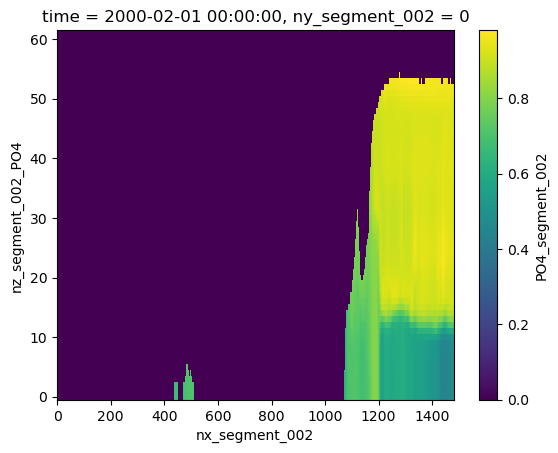

In [38]:
ds_old.PO4_segment_002[0].plot()

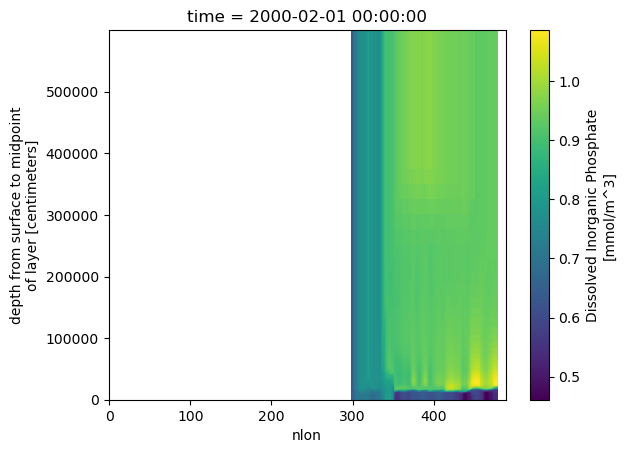

In [ ]:
ds.PO4.ffill(dim="z_t", limit = None).plot()